# Arbitrage statistique par facteurs de risque (PCA)

**Objectif du projet.** Décomposer le rendement de chaque action en une partie expliquée par des facteurs de risque communs au marché et un résidu propre à l'action :

$$
r_{i,t} = \beta_i^\top F_t + \varepsilon_{i,t}
$$

puis parier sur le retour à la moyenne du résidu cumulé, en couvrant l'exposition aux facteurs. Les facteurs $F_t$ sont estimés par une analyse en composantes principales (PCA) de la matrice de corrélation des rendements.

**Conventions utilisés**
- `tickers` : liste des 25 tickers, rangés par secteur (5 secteurs × 5 actions).
- `close_data` : DataFrame des prix de clôture ajustés, de taille $T \times N$ (une ligne par jour, une colonne par ticker).
- `returns` : DataFrame des rendements quotidiens, même format.
- `Sigma` : matrice de corrélation empirique des rendements, DataFrame $N \times N$.
- `val_propres`, `vec_propres` : valeurs propres de `Sigma` triées par ordre décroissant, et vecteurs propres associés (la colonne `vec_propres[:, k]` correspond à `val_propres[k]`). 

## 1. Données

$N=25$ grandes actions américaines liquides, réparties en 5 secteurs :

| Secteur | Tickers |
|---|---|
| Banques | JPM, BAC, C, WFC, GS |
| Énergie | XOM, CVX, COP, SLB, EOG |
| Technologie | AAPL, MSFT, NVDA, ORCL, CSCO |
| Santé | JNJ, PFE, MRK, LLY, ABT |
| Consommation de base | PG, KO, PEP, WMT, CL |

Cette structure par section est utile pour vérifier que la PCA retrouve des facteurs interprétables.
**Période.** Du 1er janvier 2010 au 1er janvier 2019 (9 ans), soit $T = 2264$ rendements quotidiens.

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels as sm
import seaborn as sns

tickers = ["JPM", "BAC", "C", "WFC", "GS",          # Banques
           "XOM", "CVX", "COP", "SLB", "EOG",       # Énergie
           "AAPL", "MSFT", "NVDA", "ORCL", "CSCO",  # Technologie
           "JNJ", "PFE", "MRK", "LLY", "ABT",       # Santé
           "PG", "KO", "PEP", "WMT", "CL"]          # Consommation de base


# On ne garde que le cours de clôture (close): dernier prix auquel un actif financier a été négocié à la fin de la journée
close_data = yf.download(tickers=tickers, start="2010-01-01", end="2019-01-01", interval="1d", group_by="ticker", threads=True)
close_data = close_data.xs("Close", axis=1, level=1)
if isinstance(close_data.columns, pd.MultiIndex):
    close_data.columns=close_data.columns.get_level_values(0)

# On supprime les lignes où il manque des données (NaN)    
close_data.dropna(inplace=True)

[*********************100%***********************]  25 of 25 completed


In [ ]:
#Vérification de la taille (2264 observations, 25 actifs)
print(close_data.shape)
close_data.head(3)

(2264, 25)


Ticker,JNJ,COP,PEP,KO,CVX,NVDA,SLB,MRK,BAC,C,...,LLY,GS,WFC,PG,CSCO,XOM,AAPL,PFE,JPM,WMT
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-04,39.778625,22.473364,36.841148,17.103199,40.537132,0.422817,45.057114,20.195465,11.977120,24.852764,...,23.375113,128.756744,17.734049,37.580555,15.769246,37.136818,6.400959,8.895801,28.012632,12.878360
2010-01-05,39.317375,22.494736,37.286316,16.896301,40.824287,0.428991,45.184677,20.277311,12.366440,25.803003,...,22.963991,131.033188,18.220896,37.592854,15.698990,37.281815,6.412028,8.768921,28.555223,12.750121
2010-01-06,39.637161,22.657145,36.913326,16.890303,40.829407,0.431736,46.191769,20.550154,12.511475,26.607067,...,23.133656,129.634583,18.246857,37.414543,15.596802,37.604042,6.310035,8.740722,28.712120,12.721622


## 2. Analyse et visualisation
Visualisation des prix

**Rq:** les niveaux de prix ne sont pas comparables. ça sert absolument à rien dans l'analyse, c'est purement pour visualiser.

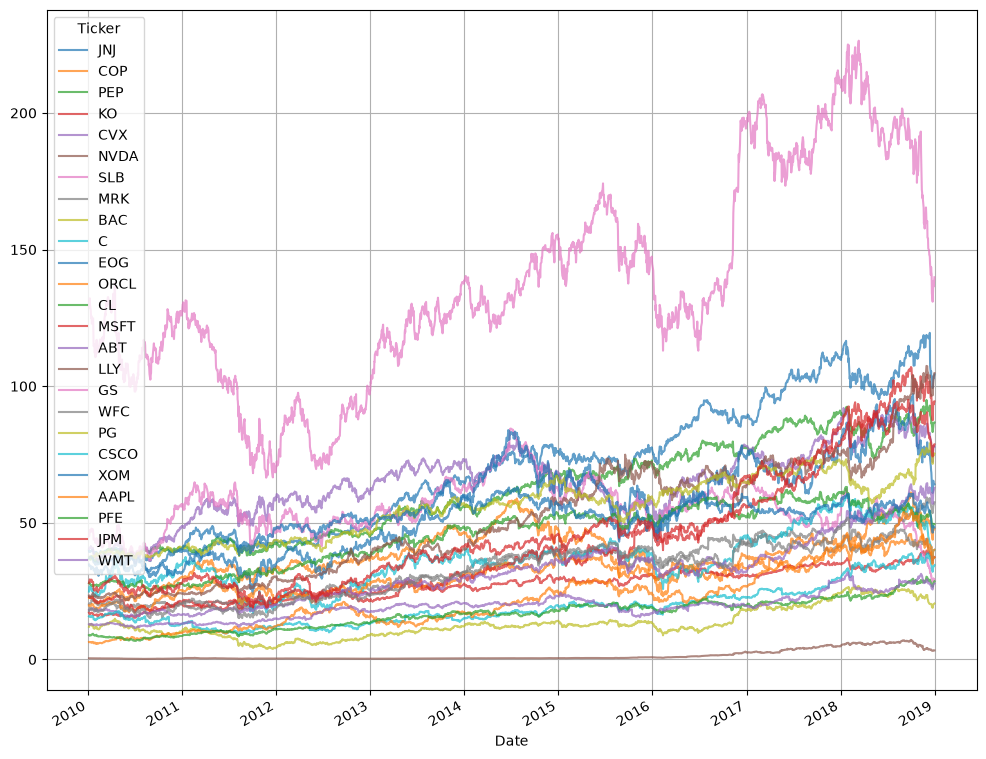

In [147]:
fig, ax = plt.subplots(figsize=(12,10))
close_data.plot(ax=ax, legend=True, alpha=0.7)
plt.grid(True)

Le **rendement quotidien** de l'action $i$ au jour $t$ est sa variation relative de prix :

$$
r^{(i)}_t = \frac{P^{(i)}_t - P^{(i)}_{t-1}}{P^{(i)}_{t-1}}
$$


In [ ]:
returns = close_data.pct_change() #percentage change, rendement quotidien
returns.dropna(inplace=True)
returns.head(2)

Ticker,JNJ,COP,PEP,KO,CVX,NVDA,SLB,MRK,BAC,C,...,LLY,GS,WFC,PG,CSCO,XOM,AAPL,PFE,JPM,WMT
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-05,-0.011595,0.000951,0.012083,-0.012097,0.007084,0.014602,0.002831,0.004053,0.032505,0.038235,...,-0.017588,0.017680,0.027453,0.000327,-0.004455,0.003904,0.001729,-0.014263,0.019370,-0.009958
2010-01-06,0.008133,0.007220,-0.010003,-0.000355,0.000125,0.006397,0.022288,0.013456,0.011728,0.031162,...,0.007388,-0.010674,0.001425,-0.004743,-0.006509,0.008643,-0.015907,-0.003216,0.005494,-0.002235


In [ ]:
# Une action par secteur pour les graphiques exploratoires
tickers_to_plot = ["JPM", "AAPL", "XOM", "JNJ"]
nb_plots = len(tickers_to_plot)

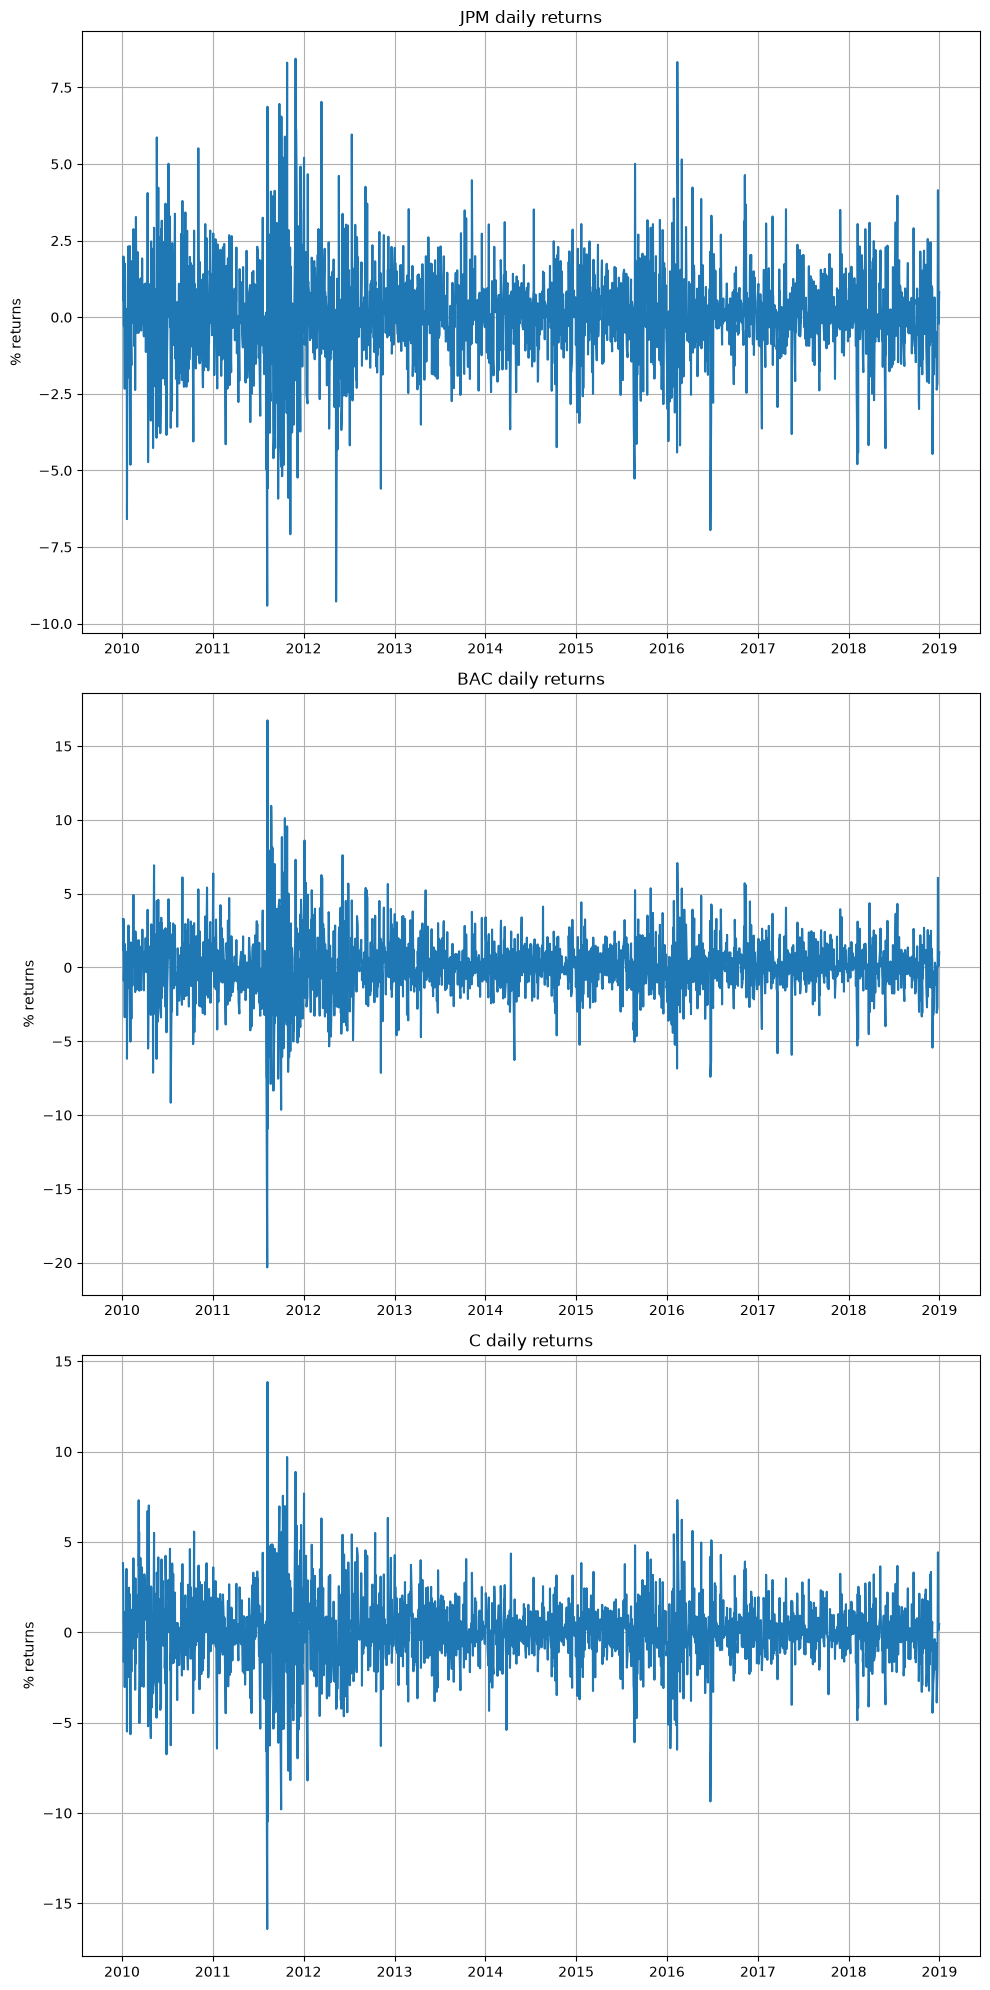

In [ ]:
# Rendements quotidiens (en %) des actions sélectionnées
fig, ax = plt.subplots(nb_plots, figsize=(10, 20))
time = np.array(returns.index)
for i in range(nb_plots):
    ax[i].plot(time, returns[tickers_to_plot[i]].values * 100)
    ax[i].set_ylabel("% returns")
    ax[i].set_title(tickers_to_plot[i] + " daily returns")
    ax[i].grid(True)
plt.tight_layout()
plt.show()

**Autocorrélation.** On vérifie si le rendement d'un jour aide à prédire celui des jours suivants. Les barres qui restent dans la zone bleue (intervalle de confiance) ne sont pas significativement différentes de 0.

On s'attend à des autocorrélations quasi nulles : **les rendements bruts sont peu prévisibles**. En effet, le rendement d'aujourd'hui ne renseigne rien sur le rendement de demain.

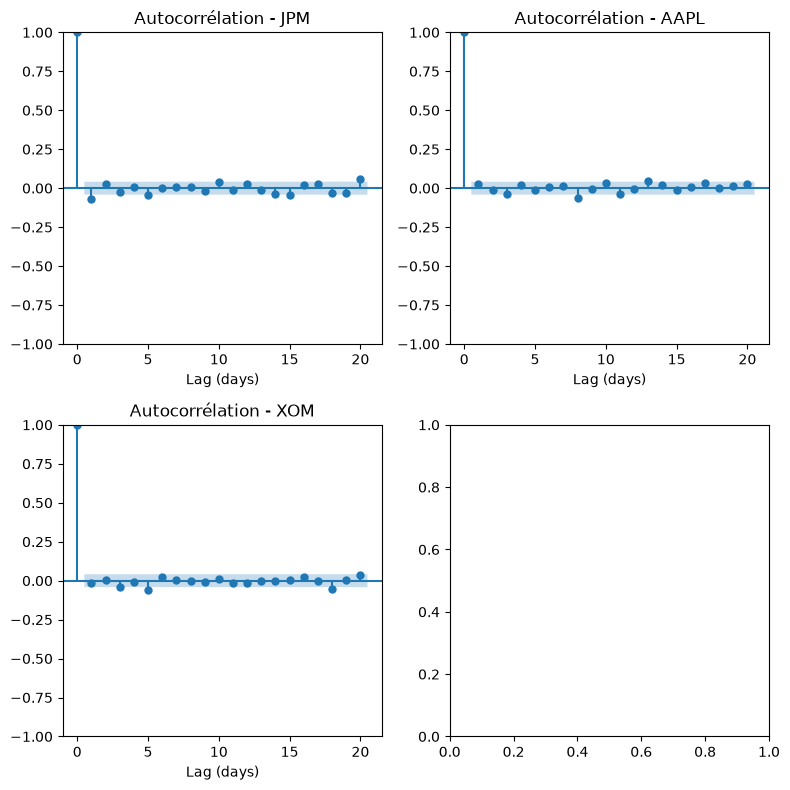

In [115]:
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(2,2, figsize=(8,8))
for ax, ticker in zip(ax.flat, tickers_to_plot):
    plot_acf(returns[ticker], lags=20, ax=ax)
    ax.set_title(f"Autocorrélation - {ticker}")
    ax.set_xlabel("Lag (days)")

plt.tight_layout()
plt.tight_layout()

**Distribution des rendements.** Par rapport à une loi normale, les rendements quotidiens sont plus concentrés autour de 0 et ont des **queues épaisses** : les mouvements extrêmes sont bien plus fréquents qu'une gaussienne ne le prévoit.

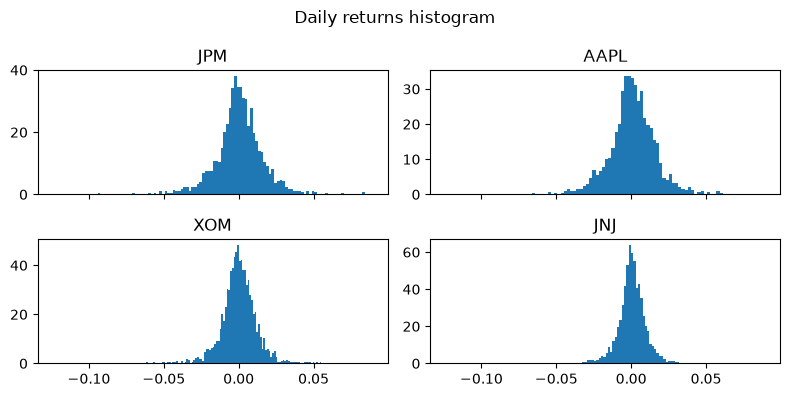

In [119]:
fig, ax= plt.subplots(2,2, sharex=True, figsize=(8,4))
plt.suptitle("Daily returns histogram")
for ax, ticker in zip(ax.flat, tickers_to_plot):
    ax.hist(returns[ticker], bins=100, density=True)
    ax.set_title(ticker)
fig.tight_layout()
plt.show()

### Matrice des corrélations $\Sigma$

S'agissant de $N=25$ actifs, la matrice de corrélation empirique $\Sigma$ est de taille $(25, 25)$. Ses coefficients sont définis par :

$$
\Sigma_{i,j} = \dfrac{C_{i,j}}{\sqrt{C_{i,i}\,C_{j,j}}}
$$

avec $C_{i,j}$ la covariance empirique de $r^{(i)}$ et $r^{(j)}$ :

$$
C_{i,j} = \frac{1}{T} \sum_{k=1}^{T} \left(r^{(i)}_k - \bar{r}^{(i)}\right)\left(r^{(j)}_k - \bar{r}^{(j)}\right)
$$ 
où $T$ est le nombre d'observations, ici $T=2264$

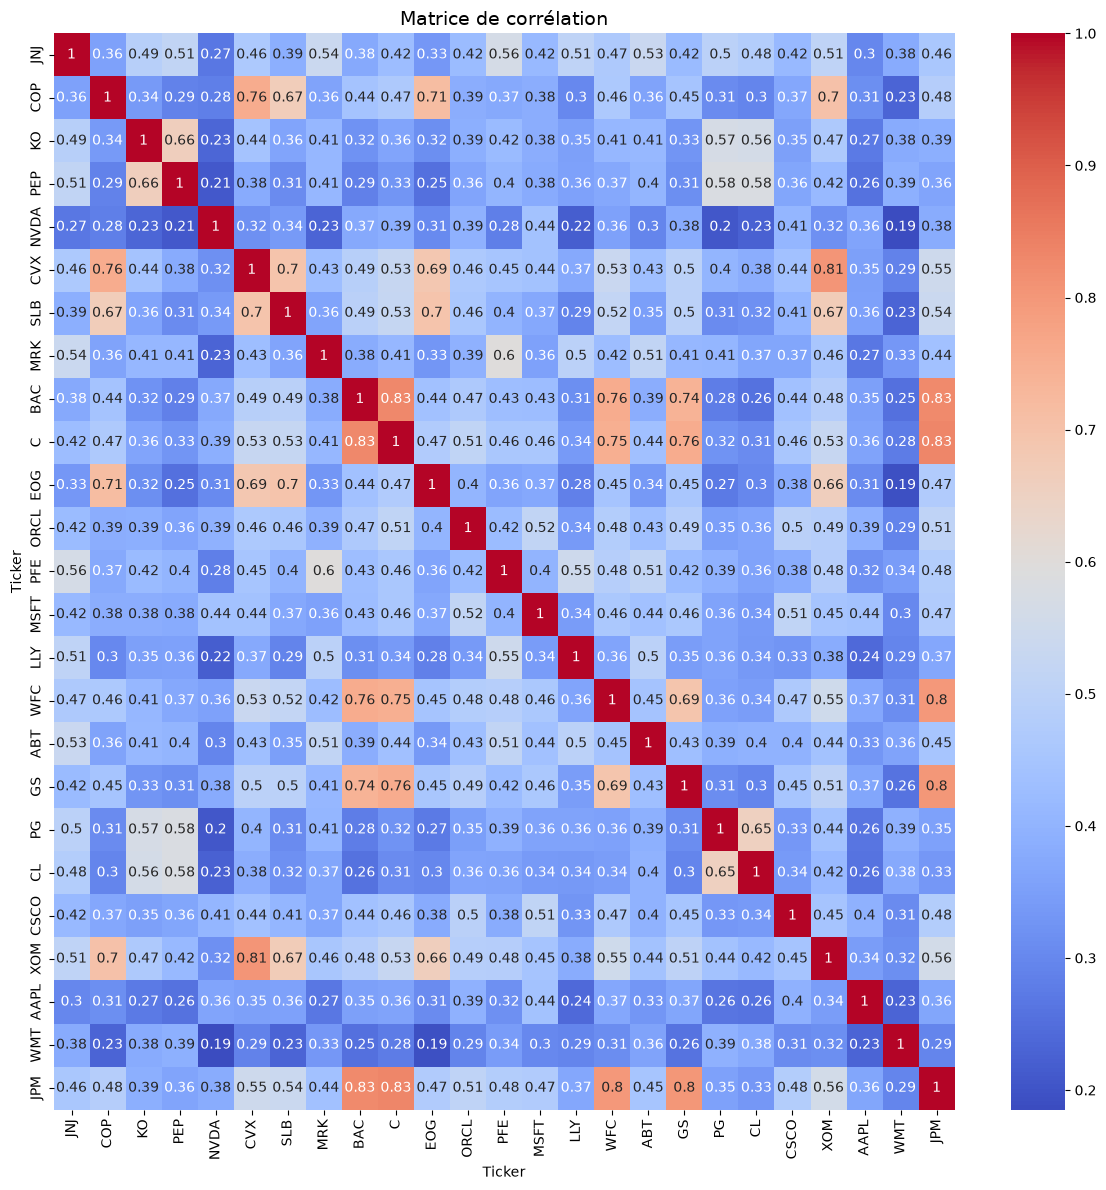

In [120]:
Sigma=returns.corr()
fig, ax = plt.subplots(1, figsize=(12,12))
sns.heatmap(Sigma, annot=True, ax=ax, cmap="coolwarm")
plt.title("Matrice de corrélation", fontsize=14)
plt.tight_layout()
plt.show()

### Vecteurs propres de $\Sigma$

$\Sigma$ est symétrique. Donc elle est diagonalisable dans une base orthonormée de vecteurs propres. Chaque vecteur propre est une direction de co-mouvement des actions. Comme $\operatorname{tr}(\Sigma) = N$, la part de variance expliquée par la $k$-ième direction vaut $\lambda_k / N$.

Les premiers vecteurs propres (plus grandes valeurs propres) définiront les facteurs de risque communs $F_t$ (eigenportfolios).

In [153]:
#Valeurs et vecteurs propres
val_propres, vec_propres = np.linalg.eigh(Sigma)

#Les ranger dans l'ordre décroissant
val_propres = val_propres[::-1]

#Contribution en % de chaque valeur propre
contrib_val_prop = val_propres/np.sum(val_propres)*100

#Affichage des valeurs propres
elts_propres = pd.DataFrame([val_propres, contrib_val_prop]).T
elts_propres.columns=['valeur propre', 'contribution (%)']
print(elts_propres.round(3))


    valeur propre  contribution (%)
0          11.131            44.524
1           2.185             8.740
2           1.545             6.181
3           1.154             4.615
4           1.092             4.369
5           0.709             2.836
6           0.638             2.552
7           0.598             2.390
8           0.534             2.134
9           0.516             2.065
10          0.513             2.052
11          0.485             1.940
12          0.466             1.862
13          0.440             1.760
14          0.387             1.549
15          0.371             1.485
16          0.329             1.317
17          0.327             1.307
18          0.300             1.199
19          0.287             1.146
20          0.257             1.029
21          0.245             0.980
22          0.183             0.730
23          0.163             0.653
24          0.146             0.585


#### Rq: 
On retrouve bien $\sum vp = \operatorname{tr}(\Sigma) = 25$ 

## Théorie de Marchenko-Pastur et filtrage du bruit

Dans le cadre d'un grand nombre d'actifs ($N=25$) sur une période historique finie, la matrice de corrélation empirique est polluée par du **bruit statistique** du aux fluctuations d'échantillonnage. 

La **loi de Marchenko-Pastur** décrit la distribution théorique des valeurs propres d'une matrice de corrélation aléatoire (bruit pur). Elle définit un seuil limite supérieur $\lambda_{max}$ :

$$\lambda_{max} = \left(1 + \sqrt{\frac{N}{T}}\right)^2$$

*(avec $N=25$ le nombre d'actifs et $T=2264$ le nombre d'observations temporelles).*
Ici, $\boxed{\lambda_{max}=1,22}$

Toutes les valeurs propres inférieures à $\lambda_{max}$ sont considérées comme du bruit.
### Débruitage de la matrice de corrélation

**Shrinkage de Ledoit-Wolf.** On combine la matrice empirique (sans biais mais bruitée) avec une cible simple et stable (par exemple l'identité) :

$$
\hat\Sigma_{\text{LW}} = (1-\delta)\,\hat\Sigma + \delta\,\text{Cible}
$$

Le coefficient $\delta \in [0,1]$ est choisi par une formule explicite qui minimise l'erreur d'estimation attendue : c'est un compromis biais-variance.

**Nettoyage spectral de Bouchaud-Potters (clipping).** On diagonalise $\hat\Sigma = V \Lambda V^\top$. Les valeurs propres supérieures au seuil $\lambda_+$ de Marchenko-Pastur sont conservées (signal), les autres sont remplacées par leur moyenne (bruit), ce qui préserve la trace $N$. On reconstruit ensuite la matrice :

$$
\hat\Sigma_{\text{clean}} = V \Lambda_{\text{clean}} V^\top
$$

puis on remet sa diagonale à 1 pour retrouver une matrice de corrélation.